[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/calculus-and-optimization/derivatives-and-taylor-series/notebook.ipynb)

# Derivatives and Taylor Series: hands-on

This notebook goes with the [topic README](README.md). You will watch secant lines turn into a tangent, compute a derivative from its limit definition by table and with SymPy, plot a function next to its derivative, see why $|x|$ and ReLU have no slope at $0$, check the differentiation rules and the chain rule, study the sigmoid and its largest slope of $\frac14$, measure how the error of a tangent-line approximation shrinks, find and classify critical points, watch Taylor polynomials close in on $e^x$, $\cos x$, and $\ln(1+x)$, see a radius of convergence, compare a linear and a quadratic model, write a forward-mode automatic differentiation class from scratch, and differentiate a tiny scalar network. All data are invented or computed on the spot. It uses NumPy, SymPy, and Matplotlib, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so the code compares floats with `np.isclose` and `np.allclose`, never `==`.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from math import factorial

plt.rcParams["figure.dpi"] = 52
plt.rcParams["axes.titlesize"] = 9
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["font.size"] = 8
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
np.set_printoptions(precision=6, suppress=True)
x = sp.symbols("x")            # the SymPy symbol used in the symbolic cells below
sigmoid = lambda z: 1 / (1 + np.exp(-z))

## 1. Secant slopes and the tangent

The slope of a curve at one point is found by drawing a **secant line** through two points and sliding the second toward the first. For $f(x) = x^2$ at $a = 3$, the secant through $x = 3$ and $x = 3 + h$ has slope $\frac{f(3+h) - f(3)}{h}$, which works out to $6 + h$.

     h   secant slope
     2         8.0000
     1         7.0000
   0.5         6.5000
   0.1         6.1000
  0.01         6.0100


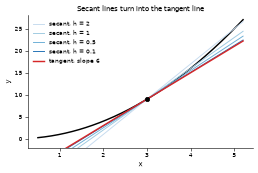

In [2]:
f = lambda t: t**2
a = 3.0
print(f"{'h':>6} {'secant slope':>14}")
for h in [2, 1, 0.5, 0.1, 0.01]:
    print(f"{h:>6g} {(f(a + h) - f(a)) / h:>14.4f}")

t = np.linspace(0.5, 5.2, 300)
fig, ax = plt.subplots(figsize=(5.6, 3.3))
ax.plot(t, f(t), "k", lw=2)
for h, col in [(2, "#c6dbef"), (1, "#9ecae1"), (0.5, "#6baed6"), (0.1, "#2171b5")]:
    m = (f(a + h) - f(a)) / h
    ax.plot(t, f(a) + m * (t - a), color=col, lw=1.3, label=f"secant, h = {h:g}")
ax.plot(t, f(a) + 6 * (t - a), color="#d62728", lw=2, label="tangent, slope 6")
ax.plot([a], [f(a)], "ko")
ax.set_ylim(-2, 28); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Secant lines turn into the tangent line")
plt.show()

## 2. The limit definition, by table and by SymPy

The derivative is $f'(a) = \lim_{h\to0}\frac{f(a+h) - f(a)}{h}$. Here are difference quotients (with a small $h$ from each side) for four functions whose derivatives we know: $x^2$ at $3$ (slope $6$), $\sin x$ at $1$ (slope $\cos 1$), $e^x$ at $0$ (slope $1$), and $\ln x$ at $2$ (slope $\frac12$).

In [3]:
cases = [("x^2 at 3", lambda t: t**2, 3.0, 6.0),
         ("sin at 1", np.sin, 1.0, np.cos(1.0)),
         ("exp at 0", np.exp, 0.0, 1.0),
         ("ln at 2", np.log, 2.0, 0.5)]
print(f"{'case':>9} {'h=-0.001':>10} {'h=+0.001':>10} {'exact':>10}")
for name, fn, a0, true in cases:
    left = (fn(a0 - 1e-3) - fn(a0)) / (-1e-3)
    right = (fn(a0 + 1e-3) - fn(a0)) / 1e-3
    print(f"{name:>9} {left:>10.5f} {right:>10.5f} {true:>10.5f}")

     case   h=-0.001   h=+0.001      exact
 x^2 at 3    5.99900    6.00100    6.00000
 sin at 1    0.54072    0.53988    0.54030
 exp at 0    0.99950    1.00050    1.00000
  ln at 2    0.50013    0.49988    0.50000


SymPy can take the limit symbolically, with a general point $a$, which gives the **derivative function** at once. These are the two worked examples from the lesson ($x^2$ and $\frac1x$).

In [4]:
a, h = sp.symbols("a h")
for expr in [x**2, 1 / x, sp.sqrt(x)]:
    quotient = (expr.subs(x, a + h) - expr.subs(x, a)) / h
    print(f"f(x) = {expr}:  f'(a) = {sp.limit(quotient, h, 0)}   (sp.diff gives {sp.diff(expr, x).subs(x, a)})")

f(x) = x**2:  f'(a) = 2*a   (sp.diff gives 2*a)
f(x) = 1/x:  f'(a) = -1/a**2   (sp.diff gives -1/a**2)
f(x) = sqrt(x):  f'(a) = 1/(2*sqrt(a))   (sp.diff gives 1/(2*sqrt(a)))


## 3. A function and its derivative

The sign of $f'$ says whether $f$ rises or falls, and $f'(x) = 0$ marks the flat spots. For $f(x) = x^3 - 6x^2 + 9x + 1$ we have $f'(x) = 3x^2 - 12x + 9 = 3(x-1)(x-3)$.

f'(x) = 3*(x - 3)*(x - 1)   zeros: [1, 3]


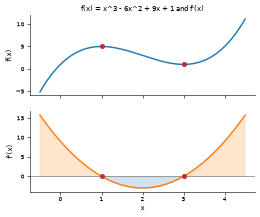

f'(0) =    9  ->  f is rising near x = 0
f'(2) =   -3  ->  f is falling near x = 2
f'(4) =    9  ->  f is rising near x = 4


In [5]:
f_expr = x**3 - 6*x**2 + 9*x + 1
df_expr = sp.diff(f_expr, x)
print("f'(x) =", sp.factor(df_expr), "  zeros:", sp.solve(df_expr, x))
F, dF = sp.lambdify(x, f_expr), sp.lambdify(x, df_expr)

t = np.linspace(-0.5, 4.5, 400)
fig, axs = plt.subplots(2, 1, figsize=(5.6, 4.4), sharex=True)
axs[0].plot(t, F(t), color="C0", lw=2)
axs[0].plot([1, 3], [F(1), F(3)], "o", color="C3")
axs[0].set_ylabel("f(x)"); axs[0].set_title("f(x) = x^3 - 6x^2 + 9x + 1 and f'(x)")
axs[1].plot(t, dF(t), color="C1", lw=2); axs[1].axhline(0, color="gray", lw=1)
axs[1].fill_between(t, dF(t), 0, where=dF(t) > 0, color="C1", alpha=0.2)
axs[1].fill_between(t, dF(t), 0, where=dF(t) < 0, color="C0", alpha=0.2)
axs[1].plot([1, 3], [0, 0], "o", color="C3")
axs[1].set_ylabel("f'(x)"); axs[1].set_xlabel("x")
plt.show()
for pt in [0, 2, 4]:
    print(f"f'({pt}) = {dF(pt):>4.0f}  ->  f is {'rising' if dF(pt) > 0 else 'falling'} near x = {pt}")

## 4. Corners: $|x|$ and ReLU

At $x = 0$ the secant slopes of $|x|$ are $-1$ from the left and $+1$ from the right, so there is no derivative there. ReLU, $\max(0, x)$, has slopes $0$ and $1$. Two more ways to fail: a **cusp** ($x^{2/3}$, where the secant slopes go to $-\infty$ on one side and $+\infty$ on the other) and a **vertical tangent** ($x^{1/3}$, where both sides go to $+\infty$).

In [6]:
shapes = {"|x|": np.abs, "ReLU": lambda t: np.maximum(0, t),
          "x^(2/3)": lambda t: np.cbrt(t) ** 2, "x^(1/3)": np.cbrt}
print(f"{'h':>8} " + " ".join(f"{n + ' L/R':>20}" for n in shapes))
for h in [1e-1, 1e-3, 1e-5]:
    row = []
    for fn in shapes.values():
        row.append(f"{(fn(-h) - fn(0)) / (-h) + 0.0:>9.1f} /{(fn(h) - fn(0)) / h + 0.0:>9.1f}")
    print(f"{h:>8g} " + " ".join(f"{r:>20}" for r in row))

       h              |x| L/R             ReLU L/R          x^(2/3) L/R          x^(1/3) L/R
     0.1      -1.0 /      1.0       0.0 /      1.0      -2.2 /      2.2       4.6 /      4.6
   0.001      -1.0 /      1.0       0.0 /      1.0     -10.0 /     10.0     100.0 /    100.0
   1e-05      -1.0 /      1.0       0.0 /      1.0     -46.4 /     46.4    2154.4 /   2154.4


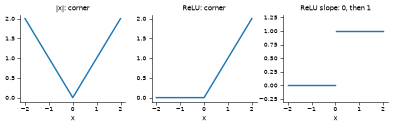

SymPy: d/dx |x| = sign(xr)    (sign(x) is -1, +1, and 0 at x = 0 by convention)


In [7]:
t = np.linspace(-2, 2, 401)
fig, axs = plt.subplots(1, 3, figsize=(7.6, 2.5))
axs[0].plot(t, np.abs(t), lw=2); axs[0].set_title("|x|: corner")
axs[1].plot(t, np.maximum(0, t), lw=2); axs[1].set_title("ReLU: corner")
d = np.where(t > 0, 1.0, np.where(t < 0, 0.0, np.nan))      # ReLU's slope; undefined (nan) at exactly 0
axs[2].plot(t, d, lw=2); axs[2].set_title("ReLU slope: 0, then 1"); axs[2].set_ylim(-0.3, 1.3)
for a_ in axs: a_.set_xlabel("x")
plt.tight_layout(); plt.show()
xr = sp.symbols("xr", real=True)          # tell SymPy x is real, so |x| differentiates cleanly
print("SymPy: d/dx |x| =", sp.diff(sp.Abs(xr), xr), "   (sign(x) is -1, +1, and 0 at x = 0 by convention)")

## 5. The rules, checked with SymPy

For each rule we write the formula from the lesson as a function of the two pieces, then ask SymPy whether the formula minus SymPy's own derivative simplifies to $0$.

In [8]:
f_, g_ = sp.exp(x), x**2 + 1          # two sample functions for the product and quotient rules
checks = {
    "power x^5":        (sp.diff(x**5, x),                       5 * x**4),
    "power 1/x":        (sp.diff(1 / x, x),                      -x**-2),
    "power sqrt(x)":    (sp.diff(sp.sqrt(x), x),                 1 / (2 * sp.sqrt(x))),
    "sum":              (sp.diff(f_ + g_, x),                    sp.diff(f_, x) + sp.diff(g_, x)),
    "constant multiple":(sp.diff(7 * g_, x),                     7 * sp.diff(g_, x)),
    "product":          (sp.diff(f_ * g_, x),                    sp.diff(f_, x) * g_ + f_ * sp.diff(g_, x)),
    "quotient":         (sp.diff(f_ / g_, x),                    (sp.diff(f_, x) * g_ - f_ * sp.diff(g_, x)) / g_**2),
    "exp":              (sp.diff(sp.exp(x), x),                  sp.exp(x)),
    "ln":               (sp.diff(sp.log(x), x),                  1 / x),
    "sin":              (sp.diff(sp.sin(x), x),                  sp.cos(x)),
    "cos":              (sp.diff(sp.cos(x), x),                  -sp.sin(x)),
}
for name, (by_sympy, by_rule) in checks.items():
    print(f"{name:<18} rule agrees with SymPy: {sp.simplify(by_sympy - by_rule) == 0}")

power x^5          rule agrees with SymPy: True
power 1/x          rule agrees with SymPy: True
power sqrt(x)      rule agrees with SymPy: True
sum                rule agrees with SymPy: True
constant multiple  rule agrees with SymPy: True
product            rule agrees with SymPy: True


quotient           rule agrees with SymPy: True
exp                rule agrees with SymPy: True
ln                 rule agrees with SymPy: True
sin                rule agrees with SymPy: True
cos                rule agrees with SymPy: True


## 6. The chain rule, step by step

For $y = e^{\sin(x^2)}$ there are three nested functions: $u = x^2$, $v = \sin u$, $y = e^v$. The chain rule multiplies the three local slopes: $\frac{dy}{dx} = \frac{dy}{dv}\cdot\frac{dv}{du}\cdot\frac{du}{dx} = e^v\cdot\cos u\cdot 2x$.

In [9]:
x0 = 1.0
u = x0**2;  v = np.sin(u);  y = np.exp(v)                 # forward pass: each step feeds the next
du_dx, dv_du, dy_dv = 2 * x0, np.cos(u), np.exp(v)        # the three local slopes
print(f"u = {u:.4f}, v = {v:.4f}, y = {y:.4f}")
print(f"local slopes: du/dx = {du_dx:.4f}, dv/du = {dv_du:.4f}, dy/dv = {dy_dv:.4f}")
chain = dy_dv * dv_du * du_dx
sym = float(sp.diff(sp.exp(sp.sin(x**2)), x).subs(x, x0))
fd = (np.exp(np.sin((x0 + 1e-6)**2)) - np.exp(np.sin((x0 - 1e-6)**2))) / 2e-6
print(f"product of slopes = {chain:.6f}   sympy = {sym:.6f}   finite difference = {fd:.6f}")
print(np.isclose(chain, sym), np.isclose(chain, fd))

u = 1.0000, v = 0.8415, y = 2.3198
local slopes: du/dx = 2.0000, dv/du = 0.5403, dy/dv = 2.3198
product of slopes = 2.506762   sympy = 2.506762   finite difference = 2.506762
True True


Two more nested functions, both from the lesson, and the implicit-differentiation example $x^2 + y^2 = 25$:

In [10]:
print("(3x+1)^5      ->", sp.factor(sp.diff((3*x + 1)**5, x)))
print("sin(x^2)      ->", sp.diff(sp.sin(x**2), x))
print("e^(-x)        ->", sp.diff(sp.exp(-x), x))
print("x^x           ->", sp.simplify(sp.diff(x**x, x)), "  (logarithmic differentiation gives x^x (ln x + 1))")
yf = sp.Function("y")
implicit = sp.diff(x**2 + yf(x)**2 - 25, x)               # differentiate the circle equation in x
slope = sp.solve(implicit, sp.diff(yf(x), x))[0]
print("circle: y' =", slope, "  at (3, 4):", slope.subs({x: 3, yf(x): 4}))

(3x+1)^5      -> 15*(3*x + 1)**4
sin(x^2)      -> 2*x*cos(x**2)
e^(-x)        -> -exp(-x)
x^x           -> x**x*(log(x) + 1)   (logarithmic differentiation gives x^x (ln x + 1))
circle: y' = -x/y(x)   at (3, 4): -3/4


## 7. The sigmoid and its slope

The chain rule gives $\sigma'(x) = \sigma(x)\,(1 - \sigma(x))$. The product $s(1-s)$ is biggest at $s = \frac12$, where it equals $\frac14$. So the slope of a sigmoid never exceeds $0.25$, and it fades in both tails.

SymPy's derivative: exp(-x)/(1 + exp(-x))**2
equals sigma(1 - sigma) on the grid: True
largest slope = 0.2500 at x = 0.0
sigma'(0) = 0.250000
sigma'(2) = 0.104994
sigma'(4) = 0.017663
sigma'(8) = 0.000335


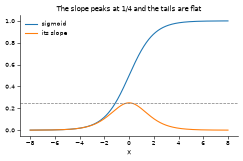

In [11]:
dsig_sym = sp.diff(1 / (1 + sp.exp(-x)), x)
dsig = sp.lambdify(x, dsig_sym, "numpy")
z = np.linspace(-8, 8, 801)
print("SymPy's derivative:", dsig_sym)
print("equals sigma(1 - sigma) on the grid:", np.allclose(dsig(z), sigmoid(z) * (1 - sigmoid(z))))
print(f"largest slope = {np.max(sigmoid(z) * (1 - sigmoid(z))):.4f} at x = {z[np.argmax(sigmoid(z) * (1 - sigmoid(z)))]:.1f}")
for pt in [0, 2, 4, 8]:
    print(f"sigma'({pt}) = {dsig(float(pt)):.6f}")

fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.plot(z, sigmoid(z), label="sigmoid"); ax.plot(z, sigmoid(z) * (1 - sigmoid(z)), label="its slope")
ax.axhline(0.25, color="gray", ls="--", lw=1); ax.legend(frameon=False); ax.set_xlabel("x")
ax.set_title("The slope peaks at 1/4 and the tails are flat")
plt.show()

**Saturation through layers.** A signal sent backward through $k$ sigmoid layers is multiplied by one slope per layer, at most $0.25$ each time (the weights also multiply it, so this is only the activation's share). For comparison, tanh has slope $1 - \tanh^2 \le 1$ and ReLU has slope $0$ or $1$.

In [12]:
for k in [1, 2, 5, 10, 20]:
    print(f"k = {k:>2} sigmoid layers: best-case factor {0.25**k:.2e}")
tanh_slope = 1 - np.tanh(z) ** 2
print("tanh slope max:", tanh_slope.max(), "  tanh(x) = 2*sigmoid(2x) - 1 matches:", np.allclose(np.tanh(z), 2 * sigmoid(2 * z) - 1))

k =  1 sigmoid layers: best-case factor 2.50e-01
k =  2 sigmoid layers: best-case factor 6.25e-02
k =  5 sigmoid layers: best-case factor 9.77e-04
k = 10 sigmoid layers: best-case factor 9.54e-07
k = 20 sigmoid layers: best-case factor 9.09e-13
tanh slope max: 1.0   tanh(x) = 2*sigmoid(2x) - 1 matches: True


## 8. Linear approximation and its error

Near $a$, $f(x) \approx f(a) + f'(a)(x - a)$. For $\sqrt{x}$ at $a = 4$ this is $2 + \frac{x-4}{4}$. The error should shrink like (distance)$^2$: ten times closer, a hundred times smaller. The last column divides by $d^2$ and settles near $\frac{1}{64}$.

In [13]:
d = np.array([1.0, 0.1, 0.01, 0.001])
approx = 2 + d / 4
err = np.abs(np.sqrt(4 + d) - approx)
print(f"{'d':>7} {'approx':>10} {'true':>10} {'error':>10} {'error/d^2':>10}")
for di, ap, tr, er in zip(d, approx, np.sqrt(4 + d), err):
    print(f"{di:>7g} {ap:>10.6f} {tr:>10.6f} {er:>10.2e} {er / di**2:>10.5f}")
print("1/64 =", 1 / 64)

      d     approx       true      error  error/d^2
      1   2.250000   2.236068   1.39e-02    0.01393
    0.1   2.025000   2.024846   1.54e-04    0.01543
   0.01   2.002500   2.002498   1.56e-06    0.01561
  0.001   2.000250   2.000250   1.56e-08    0.01562
1/64 = 0.015625


sqrt at 4: fitted slope of log(error) vs log(distance) = 1.989
 sin at 1: fitted slope of log(error) vs log(distance) = 2.014
 exp at 0: fitted slope of log(error) vs log(distance) = 2.033


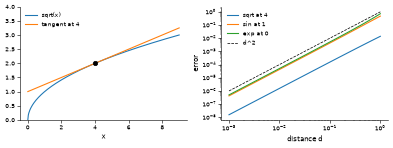

In [14]:
dd = np.logspace(-3, 0, 40)
fig, axs = plt.subplots(1, 2, figsize=(7.6, 2.9))
tt = np.linspace(0, 9, 300)
axs[0].plot(tt, np.sqrt(tt), label="sqrt(x)"); axs[0].plot(tt, 2 + (tt - 4) / 4, label="tangent at 4")
axs[0].plot([4], [2], "ko"); axs[0].set_ylim(0, 4); axs[0].legend(frameon=False); axs[0].set_xlabel("x")
for fn, dfn, a0, lab in [(np.sqrt, lambda s: 0.5 / np.sqrt(s), 4.0, "sqrt at 4"), (np.sin, np.cos, 1.0, "sin at 1"), (np.exp, np.exp, 0.0, "exp at 0")]:
    e = np.abs(fn(a0 + dd) - (fn(a0) + dfn(a0) * dd))
    axs[1].loglog(dd, e, label=lab)
    print(f"{lab:>9}: fitted slope of log(error) vs log(distance) = {np.polyfit(np.log(dd), np.log(e), 1)[0]:.3f}")
axs[1].loglog(dd, dd**2, "k--", lw=1, label="d^2"); axs[1].legend(frameon=False); axs[1].set_xlabel("distance d"); axs[1].set_ylabel("error")
plt.tight_layout(); plt.show()

## 9. Critical points and the derivative tests

A **critical point** is where $f' = 0$ (or does not exist). The first derivative test looks at the sign of $f'$ on each side, and the second derivative test looks at the sign of $f''$ there. We run both on the cubic from section 3 and on the quartic $x^4 - 2x^2$.

In [15]:
def classify(expr):
    d1, d2 = sp.diff(expr, x), sp.diff(expr, x, 2)
    for c in sorted(sp.solve(d1, x), key=float):
        left, right = d1.subs(x, c - sp.Rational(1, 100)), d1.subs(x, c + sp.Rational(1, 100))
        first = "max" if (left > 0 and right < 0) else "min" if (left < 0 and right > 0) else "neither"
        s = d2.subs(x, c)
        second = "min" if s > 0 else "max" if s < 0 else "inconclusive"
        print(f"  x = {c}: f = {expr.subs(x, c)}, sign of f' goes {'+' if left > 0 else '-'} to {'+' if right > 0 else '-'} ({first}); f'' = {s} ({second})")

for e in [x**3 - 6*x**2 + 9*x + 1, x**4 - 2*x**2, x**3]:
    print(e); classify(e)

x**3 - 6*x**2 + 9*x + 1
  x = 1: f = 5, sign of f' goes + to - (max); f'' = -6 (max)
  x = 3: f = 1, sign of f' goes - to + (min); f'' = 6 (min)
x**4 - 2*x**2
  x = -1: f = -1, sign of f' goes - to + (min); f'' = 8 (min)
  x = 0: f = 0, sign of f' goes + to - (max); f'' = -4 (max)
  x = 1: f = -1, sign of f' goes - to + (min); f'' = 8 (min)
x**3
  x = 0: f = 0, sign of f' goes + to + (neither); f'' = 0 (inconclusive)


The one-variable least-squares minimum from the lesson: fit $\hat y = wx$ to $(1, 2.1), (2, 3.9), (3, 6.2)$ by minimizing $L(w) = \sum (w x_i - y_i)^2$. Setting $L'(w) = 0$ gives $w = \frac{\sum x_i y_i}{\sum x_i^2}$.

In [16]:
xi, yi = np.array([1.0, 2.0, 3.0]), np.array([2.1, 3.9, 6.2])
w = sp.symbols("w")
L = sum((w * a_ - b_)**2 for a_, b_ in zip(xi, yi))
w_star = sp.solve(sp.diff(L, w), w)[0]
print("L'(w) =", sp.expand(sp.diff(L, w)), "  w* =", float(w_star), "  L''(w) =", sp.diff(L, w, 2), "(positive, so a minimum)")
print("matches sum(xy)/sum(x^2):", np.isclose(float(w_star), (xi @ yi) / (xi @ xi)),
      " and np.linalg.lstsq:", np.isclose(float(w_star), np.linalg.lstsq(xi[:, None], yi, rcond=None)[0][0]))

L'(w) = 28.0*w - 57.0   w* = 2.0357142857142856   L''(w) = 28.0000000000000 (positive, so a minimum)
matches sum(xy)/sum(x^2): True  and np.linalg.lstsq: True


## 10. Concavity and inflection points

$f''$ says whether the slope is increasing ($f'' > 0$, concave up) or decreasing ($f'' < 0$, concave down). An inflection point is where it changes sign. The cubic has $f''(x) = 6x - 12$, so the inflection point is $x = 2$. The curvature at a flat spot is $|f''|$: compare $x^2$ and $10x^2$.

f''(x) = 6*(x - 2)   inflection at x = [2]


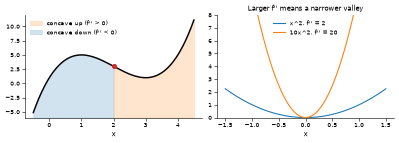

In [17]:
print("f''(x) =", sp.diff(f_expr, x, 2), "  inflection at x =", sp.solve(sp.diff(f_expr, x, 2), x))
F2 = sp.lambdify(x, sp.diff(f_expr, x, 2))
t = np.linspace(-0.5, 4.5, 400)
fig, axs = plt.subplots(1, 2, figsize=(7.6, 2.8))
axs[0].plot(t, F(t), "k", lw=2)
axs[0].fill_between(t, F(t), -6, where=F2(t) > 0, color="C1", alpha=0.2, label="concave up (f'' > 0)")
axs[0].fill_between(t, F(t), -6, where=F2(t) < 0, color="C0", alpha=0.2, label="concave down (f'' < 0)")
axs[0].plot([2], [F(2)], "o", color="C3"); axs[0].legend(frameon=False, loc="upper left"); axs[0].set_xlabel("x"); axs[0].set_ylim(-6, 12)
s_ = np.linspace(-1.5, 1.5, 200)
axs[1].plot(s_, s_**2, label="x^2, f'' = 2"); axs[1].plot(s_, 10 * s_**2, label="10x^2, f'' = 20")
axs[1].set_ylim(0, 8); axs[1].legend(frameon=False); axs[1].set_xlabel("x"); axs[1].set_title("Larger f'' means a narrower valley")
plt.tight_layout(); plt.show()

## 11. Taylor polynomials

The degree-$n$ Taylor polynomial around $a$ is $T_n(x) = \sum_{k=0}^{n}\frac{f^{(k)}(a)}{k!}(x - a)^k$. SymPy's `series` builds the Maclaurin polynomials ($a = 0$) for us, and we plot them for $e^x$, $\cos x$, and $\ln(1+x)$.

  exp(x): 1 + x + x**2/2 + x**3/6 + x**4/24 + x**5/120 + O(x**6)
  cos(x): 1 - x**2/2 + x**4/24 - x**6/720 + x**8/40320 + O(x**9)


 ln(1+x): x - x**2/2 + x**3/3 - x**4/4 + x**5/5 + O(x**6)
 1/(1-x): 1 + x + x**2 + x**3 + x**4 + x**5 + O(x**6)
  sin(x): x - x**3/6 + x**5/120 - x**7/5040 + O(x**8)


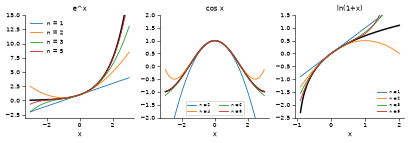

In [18]:
for name, expr, n in [("exp(x)", sp.exp(x), 5), ("cos(x)", sp.cos(x), 8), ("ln(1+x)", sp.log(1 + x), 5), ("1/(1-x)", 1 / (1 - x), 5), ("sin(x)", sp.sin(x), 7)]:
    print(f"{name:>8}: {sp.series(expr, x, 0, n + 1)}")

def maclaurin(expr, n):
    poly = sp.series(expr, x, 0, n + 1).removeO()
    return sp.lambdify(x, poly, "numpy")

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2.8))
t = np.linspace(-3, 3, 500)
axs[0].plot(t, np.exp(t), "k", lw=2)
for n in [1, 2, 3, 5]: axs[0].plot(t, maclaurin(sp.exp(x), n)(t), lw=1.2, label=f"n = {n}")
axs[0].set_ylim(-3, 15); axs[0].legend(frameon=False); axs[0].set_title("e^x")
axs[1].plot(t, np.cos(t), "k", lw=2)
for n in [2, 4, 6, 8]: axs[1].plot(t, maclaurin(sp.cos(x), n)(t), lw=1.2, label=f"n = {n}")
axs[1].set_ylim(-2, 2); axs[1].legend(frameon=True, framealpha=0.9, fontsize=6, loc="lower center", ncol=2); axs[1].set_title("cos x")
t2 = np.linspace(-0.9, 2.0, 500)
axs[2].plot(t2, np.log1p(t2), "k", lw=2)
for n in [1, 2, 3, 5]: axs[2].plot(t2, maclaurin(sp.log(1 + x), n)(t2), lw=1.2, label=f"n = {n}")
axs[2].set_ylim(-2.5, 1.5); axs[2].legend(frameon=False, fontsize=6, loc="lower right"); axs[2].set_title("ln(1+x)")
for a_ in axs: a_.set_xlabel("x")
plt.tight_layout(); plt.show()

**The error.** The remainder $R_n = f - T_n$ looks like the first omitted term, so it shrinks like $|x|^{n+1}$. On a log-log plot, the error of $T_n$ for $e^x$ against $|x|$ should be a line of slope $n + 1$.

degree 1: fitted slope = 2.026   (expected 2)
degree 2: fitted slope = 3.019   (expected 3)
degree 3: fitted slope = 4.016   (expected 4)
degree 4: fitted slope = 5.013   (expected 5)


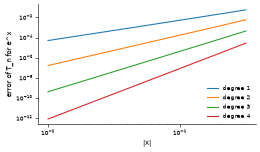


cos(0.5) by degree: [0.875, 0.87760417, 0.87758247] true: 0.87758256


In [19]:
xs_ = np.logspace(-2, -0.5, 30)
fig, ax = plt.subplots(figsize=(5.4, 3.0))
for n in [1, 2, 3, 4]:
    Tn = sum(xs_**k / factorial(k) for k in range(n + 1))
    e = np.abs(np.exp(xs_) - Tn)
    ax.loglog(xs_, e, label=f"degree {n}")
    print(f"degree {n}: fitted slope = {np.polyfit(np.log(xs_), np.log(e), 1)[0]:.3f}   (expected {n + 1})")
ax.set_xlabel("|x|"); ax.set_ylabel("error of T_n for e^x"); ax.legend(frameon=False)
plt.show()
x5 = 0.5
print("\ncos(0.5) by degree:", [round(float(maclaurin(sp.cos(x), n)(x5)), 8) for n in [2, 4, 6]], "true:", round(float(np.cos(x5)), 8))

## 12. Radius of convergence

The series $1 + x + x^2 + \dots$ equals $\frac{1}{1-x}$ only for $|x| < 1$. Outside, the partial sums run away even though the function is perfectly calm. For $\ln(1+x)$ the series $x - \frac{x^2}{2} + \frac{x^3}{3} - \dots$ converges for $-1 < x \le 1$.

geometric, x =  0.5: partial sums at n = 3, 7, 15: [1.875 1.992 2.   ]   true = 2.000
geometric, x = -0.8: partial sums at n = 3, 7, 15: [0.328 0.462 0.54 ]   true = 0.556
geometric, x =  1.2: partial sums at n = 3, 7, 15: [ 5.368 16.499 87.442]   true = -5.000
geometric, x =  1.5: partial sums at n = 3, 7, 15: [   8.125   49.258 1311.682]   true = -2.000
ln(1+x), x = 0.5: partial sum after 30 terms = 0.4055   true = 0.4055
ln(1+x), x = 1.0: partial sum after 30 terms = 0.6768   true = 0.6931
ln(1+x), x = 1.5: partial sum after 30 terms = -3783   true = 0.9163


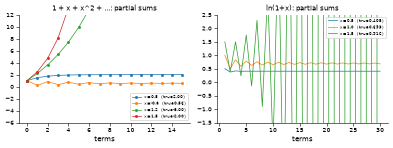

In [20]:
n = np.arange(0, 16)
fig, axs = plt.subplots(1, 2, figsize=(7.6, 2.9))
for xv in [0.5, -0.8, 1.2, 1.5]:
    ps = np.cumsum(xv ** n)
    axs[0].plot(n, ps, "o-", ms=3, lw=1, label=f"x = {xv}   (true {1 / (1 - xv):.2f})")
    print(f"geometric, x = {xv:>4}: partial sums at n = 3, 7, 15: {np.round(ps[[3, 7, 15]], 3)}   true = {1 / (1 - xv):.3f}")
axs[0].set_ylim(-6, 12); axs[0].legend(frameon=True, framealpha=0.9, fontsize=6, loc="lower right"); axs[0].set_title("1 + x + x^2 + ...: partial sums"); axs[0].set_xlabel("terms")
k = np.arange(1, 31)
for xv in [0.5, 1.0, 1.5]:
    ps = np.cumsum((-1.0) ** (k + 1) * xv ** k / k)
    axs[1].plot(k, ps, lw=1, label=f"x = {xv}   (true {np.log1p(xv):.3f})")
    print(f"ln(1+x), x = {xv}: partial sum after 30 terms = {ps[-1]:.4g}   true = {np.log1p(xv):.4f}")
axs[1].set_ylim(-1.5, 2.5); axs[1].legend(frameon=True, framealpha=0.9, fontsize=6, loc="upper right"); axs[1].set_title("ln(1+x): partial sums"); axs[1].set_xlabel("terms")
plt.tight_layout(); plt.show()

## 13. The quadratic model near a minimum

For $f(x) = e^x - 2x$ around $a = 0$, the linear model is $f(0) + f'(0)x = 1 - x$ and the quadratic model adds $\frac12 f''(0)x^2 = \frac12 x^2$. The linear model has no lowest point. The quadratic model's lowest point is $a - \frac{f'(a)}{f''(a)}$, the Newton step.

lowest point of the quadratic model: x = 1.0   true minimum: x = ln 2 = 0.693147


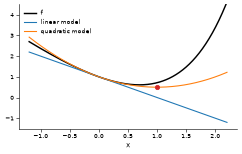


Repeat the jump (re-expand at each new point):
step 1: x = 1.00000000   error vs ln 2 = 3.07e-01
step 2: x = 0.73575888   error vs ln 2 = 4.26e-02
step 3: x = 0.69404230   error vs ln 2 = 8.95e-04
step 4: x = 0.69314758   error vs ln 2 = 4.00e-07
step 5: x = 0.69314718   error vs ln 2 = 8.02e-14

Model error at distance d from a = 0 (linear vs quadratic):
d = 0.5   linear error = 1.49e-01   quadratic error = 2.37e-02
d = 0.1   linear error = 5.17e-03   quadratic error = 1.71e-04
d = 0.01  linear error = 5.02e-05   quadratic error = 1.67e-07


In [21]:
fn = lambda s: np.exp(s) - 2 * s
fp, fpp = (lambda s: np.exp(s) - 2), np.exp
a0 = 0.0
lin = lambda s: fn(a0) + fp(a0) * (s - a0)
quad = lambda s: lin(s) + 0.5 * fpp(a0) * (s - a0) ** 2
step_to = a0 - fp(a0) / fpp(a0)
print(f"lowest point of the quadratic model: x = {step_to}   true minimum: x = ln 2 = {np.log(2):.6f}")

t = np.linspace(-1.2, 2.2, 300)
fig, ax = plt.subplots(figsize=(5.4, 3.1))
ax.plot(t, fn(t), "k", lw=2, label="f"); ax.plot(t, lin(t), label="linear model"); ax.plot(t, quad(t), label="quadratic model")
ax.plot([step_to], [quad(step_to)], "o", color="C3"); ax.set_ylim(-1.5, 4.5); ax.legend(frameon=False); ax.set_xlabel("x")
plt.show()

print("\nRepeat the jump (re-expand at each new point):")
s_ = 0.0
for step in range(1, 6):
    s_ = s_ - fp(s_) / fpp(s_)
    print(f"step {step}: x = {s_:.8f}   error vs ln 2 = {abs(s_ - np.log(2)):.2e}")
print("\nModel error at distance d from a = 0 (linear vs quadratic):")
for dist in [0.5, 0.1, 0.01]:
    print(f"d = {dist:<5} linear error = {abs(fn(dist) - lin(dist)):.2e}   quadratic error = {abs(fn(dist) - quad(dist)):.2e}")

Gradient descent steps by $-\eta f'(a)$, which trusts the linear model for a distance $\eta\,|f'(a)|$. A small $\eta$ stays where the line is accurate. Here is what happens to descent on $f(x) = e^x - 2x$ for three learning rates, starting at $x = 2$:

In [22]:
for eta in [0.05, 0.4, 1.2]:
    s_, path = 2.0, []
    for _ in range(8):
        s_ = s_ - eta * fp(s_)
        path.append(s_)
    print(f"eta = {eta:<4}: x after 1, 2, 4, 8 steps = {np.round([path[0], path[1], path[3], path[7]], 4)}   (target {np.log(2):.4f})")

eta = 0.05: x after 1, 2, 4, 8 steps = [1.7305 1.5484 1.3077 1.0452]   (target 0.6931)
eta = 0.4 : x after 1, 2, 4, 8 steps = [-0.1556  0.302   0.66    0.6931]   (target 0.6931)
eta = 1.2 : x after 1, 2, 4, 8 steps = [-4.4669 -2.0806  1.1478  1.1886]   (target 0.6931)


With $\eta = 0.05$ the line is trusted only over tiny steps, so progress is safe but slow. With $\eta = 0.4$ descent reaches the minimum in about eight steps. With $\eta = 1.2$ the first step flies far past the minimum (to about $-4.5$), where the line is a poor guide, and the iterates bounce around instead of settling.

## 14. Forward-mode automatic differentiation from scratch

A **dual number** carries a pair (value, derivative). Each operation updates both with its own rule: sums add derivatives, products use the product rule, and functions use the chain rule. Seed the input with derivative $1$ and the output's derivative is the answer. Below is a fuller version of the class from the lesson (it also divides, negates, and subtracts from the left).

In [23]:
import math

class Dual:
    def __init__(self, val, der=0.0):
        self.val, self.der = val, der
    @staticmethod
    def lift(o):
        return o if isinstance(o, Dual) else Dual(o)
    def __add__(self, o):
        o = Dual.lift(o); return Dual(self.val + o.val, self.der + o.der)
    def __sub__(self, o):
        o = Dual.lift(o); return Dual(self.val - o.val, self.der - o.der)
    def __mul__(self, o):
        o = Dual.lift(o); return Dual(self.val * o.val, self.der * o.val + self.val * o.der)
    def __truediv__(self, o):
        o = Dual.lift(o)
        return Dual(self.val / o.val, (self.der * o.val - self.val * o.der) / o.val**2)
    def __pow__(self, n):
        return Dual(self.val**n, n * self.val**(n - 1) * self.der)
    def __neg__(self):
        return Dual(-self.val, -self.der)
    __radd__, __rmul__ = __add__, __mul__
    def __rsub__(self, o):
        return Dual.lift(o) - self
    def __rtruediv__(self, o):
        return Dual.lift(o) / self

def apply(fun, dfun, u):                  # chain rule: outer slope at u.val times u.der
    return Dual(fun(u.val), dfun(u.val) * u.der)

d_exp = lambda u: apply(math.exp, math.exp, u)
d_log = lambda u: apply(math.log, lambda v: 1 / v, u)
d_sin = lambda u: apply(math.sin, math.cos, u)
d_cos = lambda u: apply(math.cos, lambda v: -math.sin(v), u)
d_relu = lambda u: apply(lambda v: max(0.0, v), lambda v: 1.0 if v > 0 else 0.0, u)
d_sigmoid = lambda u: apply(lambda v: 1 / (1 + math.exp(-v)), lambda v: (1 / (1 + math.exp(-v))) * (1 - 1 / (1 + math.exp(-v))), u)

def derivative(fun, at):
    return fun(Dual(at, 1.0)).der         # seed dx/dx = 1

Now test it against SymPy (exact) and a centered finite difference on several functions, including one with a quotient and one that mixes everything:

In [24]:
tests = {
    "x^3 - 2x + 1":            (lambda u: u**3 - 2 * u + 1,                      x**3 - 2*x + 1,                           1.7),
    "x e^x / (1 + x^2)":       (lambda u: u * d_exp(u) / (1 + u**2),             x * sp.exp(x) / (1 + x**2),               0.6),
    "e^(sin(x^2))":            (lambda u: d_exp(d_sin(u**2)),                    sp.exp(sp.sin(x**2)),                     1.0),
    "ln(1 + e^x)":             (lambda u: d_log(1 + d_exp(u)),                   sp.log(1 + sp.exp(x)),                    -0.3),
    "sigmoid(3x - 1)":         (lambda u: d_sigmoid(3 * u - 1),                  1 / (1 + sp.exp(-(3*x - 1))),             0.2),
    "cos(x) / x":              (lambda u: d_cos(u) / u,                          sp.cos(x) / x,                            2.0),
}
print(f"{'function':<20} {'autodiff':>11} {'sympy':>11} {'finite diff':>12}  agree")
for name, (dual_fn, expr, pt) in tests.items():
    auto = derivative(dual_fn, pt)
    exact = float(sp.diff(expr, x).subs(x, pt))
    plain = lambda s: dual_fn(Dual(s)).val       # the same code, run with plain numbers
    fd = (plain(pt + 1e-6) - plain(pt - 1e-6)) / 2e-6
    print(f"{name:<20} {auto:>11.6f} {exact:>11.6f} {fd:>12.6f}  {np.isclose(auto, exact) and np.isclose(auto, fd, rtol=1e-6)}")

function                autodiff       sympy  finite diff  agree
x^3 - 2x + 1            6.670000    6.670000     6.670000  True
x e^x / (1 + x^2)       1.434367    1.434367     1.434367  True
e^(sin(x^2))            2.506762    2.506762     2.506762  True
ln(1 + e^x)             0.425557    0.425557     0.425557  True
sigmoid(3x - 1)         0.720782    0.720782     0.720782  True
cos(x) / x             -0.350612   -0.350612    -0.350612  True


## 15. A tiny scalar network

$y = w_2\,\mathrm{relu}(w_1 x)$ with loss $L = (y - t)^2$. The chain is $w_1 \to z_1 = w_1 x \to h = \mathrm{relu}(z_1) \to y = w_2 h \to L$. Backpropagation by hand multiplies one local slope per link, starting at the loss:

$\frac{\partial L}{\partial y} = 2(y - t)$, $\quad\frac{\partial L}{\partial w_2} = \frac{\partial L}{\partial y}\,h$, $\quad\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial y}\,w_2\,\mathbb{1}[z_1 > 0]\,x$.

We compare the hand calculation with the dual numbers, with SymPy, and with finite differences.

In [25]:
x_in, t_, w1_0, w2_0 = 1.5, 2.0, 0.8, -0.5

def forward_and_hand_grads(w1, w2):
    z1 = w1 * x_in; h = max(0.0, z1); y = w2 * h; loss = (y - t_) ** 2
    dL_dy = 2 * (y - t_)
    return loss, dL_dy * w2 * (1.0 if z1 > 0 else 0.0) * x_in, dL_dy * h      # loss, dL/dw1, dL/dw2

loss_fn = lambda w1, w2: (w2 * d_relu(w1 * x_in) - t_) ** 2
loss0, g1_hand, g2_hand = forward_and_hand_grads(w1_0, w2_0)
g1_auto = loss_fn(Dual(w1_0, 1.0), Dual(w2_0)).der
g2_auto = loss_fn(Dual(w1_0), Dual(w2_0, 1.0)).der
W1, W2 = sp.symbols("W1 W2")
L_sym = (W2 * sp.Max(0, W1 * x_in) - t_) ** 2
g1_sym = float(sp.diff(L_sym, W1).subs({W1: w1_0, W2: w2_0}))
g2_sym = float(sp.diff(L_sym, W2).subs({W1: w1_0, W2: w2_0}))
e = 1e-6
g1_fd = (forward_and_hand_grads(w1_0 + e, w2_0)[0] - forward_and_hand_grads(w1_0 - e, w2_0)[0]) / (2 * e)
g2_fd = (forward_and_hand_grads(w1_0, w2_0 + e)[0] - forward_and_hand_grads(w1_0, w2_0 - e)[0]) / (2 * e)
print(f"loss = {loss0:.4f}")
print(f"{'':>14} {'dL/dw1':>10} {'dL/dw2':>10}")
for name, g in [("by hand", (g1_hand, g2_hand)), ("autodiff", (g1_auto, g2_auto)), ("sympy", (g1_sym, g2_sym)), ("finite diff", (g1_fd, g2_fd))]:
    print(f"{name:>14} {g[0]:>10.4f} {g[1]:>10.4f}")
print(np.allclose([g1_hand, g2_hand], [g1_auto, g2_auto]), np.allclose([g1_hand, g2_hand], [g1_sym, g2_sym]), np.allclose([g1_hand, g2_hand], [g1_fd, g2_fd], atol=1e-6))

loss = 6.7600
                   dL/dw1     dL/dw2
       by hand     3.9000    -6.2400
      autodiff     3.9000    -6.2400
         sympy     3.9000    -6.2400
   finite diff     3.9000    -6.2400
True True True


**A dead ReLU.** If $w_1 x < 0$ the ReLU outputs $0$ and its slope is $0$, so the loss has no sensitivity to $w_1$ and gradient descent cannot move it. The gradient for $w_2$ is multiplied by $h = 0$, so it vanishes too.

In [26]:
for w1_try in [0.8, -0.8]:
    loss_, g1_, g2_ = forward_and_hand_grads(w1_try, w2_0)
    print(f"w1 = {w1_try:>4}: loss = {loss_:.3f}, dL/dw1 = {g1_ + 0.0:.3f}, dL/dw2 = {g2_ + 0.0:.3f}")

w1 =  0.8: loss = 6.760, dL/dw1 = 3.900, dL/dw2 = -6.240
w1 = -0.8: loss = 4.000, dL/dw1 = 0.000, dL/dw2 = 0.000


**The logistic-loss shortcut.** For $p = \sigma(z)$ and target $y \in \{0, 1\}$, the loss $-[y\ln p + (1-y)\ln(1-p)]$ has derivative $p - y$ with respect to $z$ (the chain rule cancels the sigmoid slope). Check with a finite difference:

In [27]:
def logistic_loss(zv, yv):
    p = sigmoid(zv)
    return -(yv * np.log(p) + (1 - yv) * np.log(1 - p))

for zv, yv in [(2.0, 0), (-1.0, 1), (0.3, 1)]:
    fd = (logistic_loss(zv + 1e-6, yv) - logistic_loss(zv - 1e-6, yv)) / 2e-6
    print(f"z = {zv:>4}, y = {yv}: p - y = {sigmoid(zv) - yv:>8.5f}   finite difference = {fd:>8.5f}   agree: {np.isclose(sigmoid(zv) - yv, fd)}")

z =  2.0, y = 0: p - y =  0.88080   finite difference =  0.88080   agree: True
z = -1.0, y = 1: p - y = -0.73106   finite difference = -0.73106   agree: True
z =  0.3, y = 1: p - y = -0.42556   finite difference = -0.42556   agree: True


## Summary

- The derivative is the limit of secant slopes. SymPy computes it exactly, a difference quotient approximates it, and it fails at corners ($|x|$, ReLU), cusps, vertical tangents, and jumps.
- The rules and the chain rule agree with SymPy. The sigmoid's slope $\sigma(1-\sigma)$ peaks at $\frac14$, which is why saturating activations shrink gradients.
- A tangent line approximates with error $\propto d^2$, and a Taylor polynomial of degree $n$ with error $\propto |x - a|^{n+1}$. Series converge only inside their radius of convergence.
- Critical points are classified by the sign change of $f'$ or the sign of $f''$. A quadratic model has a lowest point where a linear one does not, which is the idea of Newton's method, while the learning rate sets how far gradient descent trusts the linear model.
- A dual-number class differentiates ordinary code exactly. Backpropagation is the chain rule run backwards through the computation.

Next, [Integrals](../integrals/README.md) reverses the process: from a rate of change back to the total change.